<a href="https://colab.research.google.com/github/sahferr/my_colab/blob/main/prepara%C3%A7%C3%A3o_de_dados_trabalho_extra.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
from pathlib import Path

drive.mount('/content/drive')
Path('/content/drive/MyDrive/endotelio').mkdir(parents=True, exist_ok=True)

Mounted at /content/drive


In [ ]:
%%writefile /content/drive/MyDrive/endotelio/funcoes.py
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from skimage.feature import peak_local_max

# ---------- Caminhos e constantes ----------
PASTA_DRIVE = Path('/content/drive/MyDrive/endotelio')
DATASET = PASTA_DRIVE / 'dataset_preparado'
ARQUIVO_MODELO = PASTA_DRIVE / 'unet_centros.pt'
EXTENSOES = ('.tiff', '.tif')
SEED = 42
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'


# ---------- Arquivos ----------
def listar_conjunto(pasta: Path) -> list[tuple[Path, Path]]:
    imgs = sorted(p for p in (pasta / 'images').iterdir() if p.suffix.lower() in EXTENSOES)
    return [(img, pasta / 'labels' / img.with_suffix('.txt').name) for img in imgs]


def carregar_cinza(caminho: Path) -> np.ndarray:
    img = cv2.imread(str(caminho), cv2.IMREAD_UNCHANGED)
    if img.ndim == 3:
        img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    if img.dtype != np.uint8:
        img = cv2.normalize(img, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
    return img


def ler_centros(txt: Path) -> pd.DataFrame:
    if txt.stat().st_size == 0:
        return pd.DataFrame(columns=['id', 'x', 'y', 'tag'])
    return pd.read_csv(txt, sep=r'\s+')


# ---------- Visualização ----------
def mostrar_etapas(etapas: dict) -> None:
    fig, eixos = plt.subplots(1, len(etapas), figsize=(4 * len(etapas), 6), squeeze=False)
    for eixo, (titulo, img) in zip(eixos[0], etapas.items()):
        eixo.imshow(img, cmap='gray')
        eixo.set_title(titulo)
        eixo.axis('off')
    plt.show()


def desenhar_pontos(img: np.ndarray, xs, ys, cor=(255, 0, 0)) -> np.ndarray:
    saida = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)
    for x, y in zip(xs, ys):
        cv2.circle(saida, (int(x), int(y)), 2, cor, -1)
    return saida


# ---------- Pré-processamento ----------
def corrigir_iluminacao(img: np.ndarray, sigma: float = 20) -> np.ndarray:
    fundo = cv2.GaussianBlur(img, (0, 0), sigma)
    return cv2.divide(img, fundo, scale=128)


def gerar_mapa(shape, centros: pd.DataFrame, sigma: float = 2.5) -> np.ndarray:
    mapa = np.zeros(shape, np.float32)
    if centros.empty:
        return mapa
    ys = centros['y'].clip(0, shape[0] - 1).astype(int)
    xs = centros['x'].clip(0, shape[1] - 1).astype(int)
    mapa[ys, xs] = 1
    mapa = cv2.GaussianBlur(mapa, (0, 0), sigma)
    return mapa / mapa.max()


def gerar_mascara(shape, centros: pd.DataFrame, margem: int = 10) -> np.ndarray:
    mask = np.zeros(shape, np.uint8)
    pts = centros[['x', 'y']].to_numpy(np.int32)
    if len(pts) >= 3:
        cv2.fillConvexPoly(mask, cv2.convexHull(pts), 1)
    for x, y in pts:
        cv2.circle(mask, (int(x), int(y)), margem, 1, -1)
    return cv2.dilate(mask, np.ones((margem, margem), np.uint8))


def ajustar_tamanho(arr: np.ndarray, mult: int = 16) -> np.ndarray:
    h, w = arr.shape
    H, W = -(-h // mult) * mult, -(-w // mult) * mult
    return np.pad(arr, ((0, H - h), (0, W - w)))


# ---------- Modelo ----------
def bloco(ent: int, sai: int) -> nn.Sequential:
    return nn.Sequential(
        nn.Conv2d(ent, sai, 3, padding=1), nn.BatchNorm2d(sai), nn.ReLU(inplace=True),
        nn.Conv2d(sai, sai, 3, padding=1), nn.BatchNorm2d(sai), nn.ReLU(inplace=True),
    )


class UNet(nn.Module):
    def __init__(self, canais=(16, 32, 64, 128, 256)):
        super().__init__()
        self.pool = nn.MaxPool2d(2)
        self.descidas, self.ups, self.subidas = nn.ModuleList(), nn.ModuleList(), nn.ModuleList()
        ent = 1
        for c in canais:
            self.descidas.append(bloco(ent, c))
            ent = c
        for c in reversed(canais[:-1]):
            self.ups.append(nn.ConvTranspose2d(ent, c, 2, stride=2))
            self.subidas.append(bloco(2 * c, c))
            ent = c
        self.saida = nn.Conv2d(ent, 1, 1)

    def forward(self, x):
        atalhos = []
        for i, desc in enumerate(self.descidas):
            x = desc(x)
            if i < len(self.descidas) - 1:
                atalhos.append(x)
                x = self.pool(x)
        for up, sub, atalho in zip(self.ups, self.subidas, reversed(atalhos)):
            x = sub(torch.cat([up(x), atalho], dim=1))
        return torch.sigmoid(self.saida(x))


def carregar_modelo() -> UNet:
    modelo = UNet().to(DEVICE)
    modelo.load_state_dict(torch.load(ARQUIVO_MODELO, map_location=DEVICE))
    modelo.eval()
    return modelo


# ---------- Reconhecimento ----------
def prever_mapa(modelo, img: np.ndarray) -> np.ndarray:
    entrada = corrigir_iluminacao(img).astype(np.float32) / 255
    x = torch.from_numpy(ajustar_tamanho(entrada)[None, None]).to(DEVICE)
    modelo.eval()
    with torch.no_grad():
        mapa = modelo(x)[0, 0].cpu().numpy()
    h, w = img.shape
    return mapa[:h, :w]


def achar_centros(mapa: np.ndarray, limiar: float = 0.3, dist_min: int = 4) -> np.ndarray:
    return peak_local_max(mapa, min_distance=dist_min, threshold_abs=limiar)

Writing /content/drive/MyDrive/endotelio/funcoes.py


In [ ]:
import sys, importlib
sys.path.append('/content/drive/MyDrive/endotelio')
import funcoes
importlib.reload(funcoes)
from funcoes import *

In [ ]:
import re
import shutil
from sklearn.model_selection import train_test_split

ORIGEM = Path('brutos')
TEST_SIZE = 0.30

In [ ]:
def limpar_nome(nome: str) -> str:
    return re.sub(r' \(\d+\)', '', nome)

In [ ]:
def subir_arquivos(destino: Path) -> None:
    from google.colab import files
    destino.mkdir(exist_ok=True)
    enviados = files.upload()
    for nome, conteudo in enviados.items():
        (destino / limpar_nome(nome)).write_bytes(conteudo)
        Path(nome).unlink(missing_ok=True)
    print(f'{len(enviados)} arquivos salvos em {destino}/')

In [ ]:
subir_arquivos(ORIGEM)

Saving 72385.txt to 72385.txt
Saving 72385.tiff to 72385.tiff
Saving 72384.txt to 72384.txt
Saving 72384.tiff to 72384.tiff
Saving 72383.txt to 72383.txt
Saving 72383.tiff to 72383.tiff
Saving 72382.txt to 72382.txt
Saving 72382.tiff to 72382.tiff
Saving 72381.txt to 72381.txt
Saving 72381.tiff to 72381.tiff
Saving 72380.txt to 72380.txt
Saving 72380.tiff to 72380.tiff
Saving 72379.txt to 72379.txt
Saving 72379.tiff to 72379.tiff
Saving 72378.txt to 72378.txt
Saving 72378.tiff to 72378.tiff
Saving 72377.txt to 72377.txt
Saving 72377.tiff to 72377.tiff
Saving 72376.txt to 72376.txt
Saving 72376.tiff to 72376.tiff
Saving 72375.txt to 72375.txt
Saving 72375.tiff to 72375.tiff
Saving 72374.txt to 72374.txt
Saving 72374.tiff to 72374.tiff
Saving 72373.txt to 72373.txt
Saving 72373.tiff to 72373.tiff
Saving 72372.txt to 72372.txt
Saving 72372.tiff to 72372.tiff
Saving 72371.txt to 72371.txt
Saving 72371.tiff to 72371.tiff
Saving 72370.txt to 72370.txt
Saving 72370.tiff to 72370.tiff
Saving 7

In [ ]:
def listar_pares(origem: Path) -> list[tuple[Path, Path]]:
    pares = []
    for img in sorted(origem.iterdir()):
        txt = img.with_suffix('.txt')
        if img.suffix.lower() in EXTENSOES and txt.exists():
            pares.append((img, txt))
    return pares

In [ ]:
def copiar_pares(pares: list[tuple[Path, Path]], conjunto: str) -> None:
    pasta_img = DATASET / conjunto / 'images'
    pasta_lbl = DATASET / conjunto / 'labels'
    pasta_img.mkdir(parents=True, exist_ok=True)
    pasta_lbl.mkdir(parents=True, exist_ok=True)
    for img, txt in pares:
        shutil.copy(img, pasta_img / img.name)
        shutil.copy(txt, pasta_lbl / txt.name)

In [ ]:
pares = listar_pares(ORIGEM)
if not pares:
    raise FileNotFoundError(f'Nenhum par imagem + .txt encontrado em {ORIGEM}/')

treino, teste = train_test_split(pares, test_size=TEST_SIZE, random_state=SEED)
copiar_pares(treino, 'train')
copiar_pares(teste, 'test')
print(f'Pares: {len(pares)} | Treino: {len(treino)} | Teste: {len(teste)}')

Pares: 385 | Treino: 269 | Teste: 116


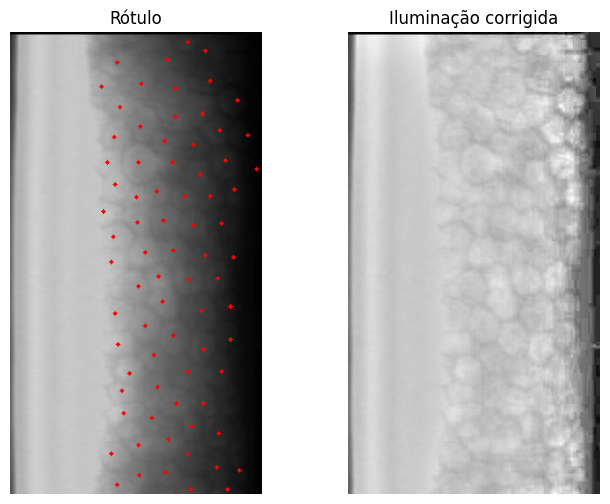

In [ ]:
img_path, txt_path = listar_conjunto(DATASET / 'train')[0]
original = carregar_cinza(img_path)
centros = ler_centros(txt_path)
mostrar_etapas({
    'Rótulo': desenhar_pontos(original, centros['x'], centros['y']),
    'Iluminação corrigida': corrigir_iluminacao(original),
})